# 🚀 Đánh Giá Benchmark Toàn Diện Method 9 Trên 4,999 Trang DocLayNet

**Mô hình:** `SpatialSidecarYOLO26` (YOLOv26 Detector + Spatial Layout Sidecar CNN 22 kênh + Zero-Gated Multi-Scale Feature Fusion tại tầng Neck P3, P4, P5)  
**Trọng số:** `methods/method9/weights/yolo26_doclaynet_best.pt` & `yolo26_sidecar_best.pt`  
**Tập dữ liệu đánh giá:** 4,999 trang tài liệu (`datasets/doclaynet_test/processed/annotations/test.json` — 66,531 ground-truth boxes thuộc 11 lớp cấu trúc DocLayNet)

---

### 📌 Tóm tắt các nhóm chỉ số đánh giá trong Notebook:
1. **Strict & Localization-only (Loose) Precision / Recall / F1** (Micro, Macro và chi tiết từng lớp tại `IoU >= 0.50`).
2. **Phân tích lỗi 2 giai đoạn (`print_error_analysis`)**:
   - **Giai đoạn 1 (Detection)** & **Giai đoạn 2 (Classification)** & **End-to-End F1**.
   - **Phân tích lỗi Tách / Gộp box (Split & Merge rates)** và các tổ hợp lớp hay bị gộp.
   - **Bảng A (Số phận GT theo lớp)**, **Bảng B (Nguồn gốc Pred theo lớp)** và **Bảng C (Confusion Matrix)**.
   - **Thang đo tham chiếu độ khít biên (`print_localization_reference` & `jitter_ceiling`)** và **Bảng tóm tắt đa ngưỡng IoU (`0.50`, `0.75`, `0.95`)**.
3. **Chuẩn quốc tế COCO mAP**:
   - Đánh giá trực tiếp trên tập box đã lọc ngưỡng tối ưu F1 (`conf >= 0.25`): `mAP@[.50:.95] = 0.697`, `mAP@50 = 0.825`, `mAP@75 = 0.751`.
   - Đánh giá trên toàn dải ngưỡng chuẩn COCO (`conf >= 0.01`, `maxDets=100`): **`mAP@[.50:.95] = 0.759`**, **`mAP@50 = 0.900`**, **`mAP@75 = 0.819`**.
4. **Trực quan hóa (Visualization)**: Biểu đồ `metrics_chart.png` và **10 ảnh đối chiếu trực tiếp Ground Truth vs. Method 9 Prediction**.

In [1]:
from pathlib import Path
import subprocess
import sys
import torch

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

METHOD = "method9"
DATASET = "doclaynet_test"
SPLIT = "test"
PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
REPORTS_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
FIGURES_DIR = ROOT / "visualization" / "figures" / f"{METHOD}_{DATASET}"

device = f"cuda ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else "cpu"
num_preds = len(list(PREDICTIONS_DIR.glob("*.json")))
print(f"Project Root   : {ROOT}")
print(f"Method         : {METHOD} (SpatialSidecarYOLO26)")
print(f"Benchmark Split: {DATASET}/{SPLIT} ({num_preds:,} prediction files ready)")
print(f"Device         : {device}")

Project Root   : d:\Semester_261\DoAnChuyenNganh\DO-AN-261
Method         : method9 (SpatialSidecarYOLO26)
Benchmark Split: doclaynet_test/test (4,999 prediction files ready)
Device         : cuda (NVIDIA GeForce RTX 4070 Laptop GPU)


## 1. Đánh Giá Toàn Diện: Strict/Loose F1, COCO mAP@[.50:.95] / mAP@50 / mAP@75 & Phân Tích Lỗi 2 Giai Đoạn (`print_error_analysis`)

Thực thi `scripts/evaluate_predictions.py` trên toàn bộ **4,999 trang** (`66,531` GT boxes) với đầy đủ các hàm phân tích lỗi mới trong `src/common/metrics.py` và hiển thị biểu đồ `metrics_chart.png`.

TAP DANH GIA: TEST (doclaynet_test) - bao cao ket qua cuoi cung
[note] Tap TEST chi de bao cao cuoi cung; chon nguong / cach map nhan tren tap valid.
Evaluation: method9 on doclaynet_test/test | 4999 images | GT=66,531 boxes | Predictions=70,090 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.849  Recall=0.894  F1=0.871  TP=59490 FP=10600 FN=7041  mean IoU=0.921
Macro (mean across 11 ground-truth classes): Precision=0.817  Recall=0.858  F1=0.834
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                 29940   31509  27541   3968   2399    0.874    0.920    0.896
List-item            10522   10875   9505   1370   1017    0.874    0.903    0.888
Section-header        8550    9251   7536   1715   1014    0.815    0.881    0.847
Page-footer           3994    4271   3618    653    376    0.847    0.906    0.875
Picture               3534    3832   2919    913    615    0.762    0.826    0.793
Page-header           336

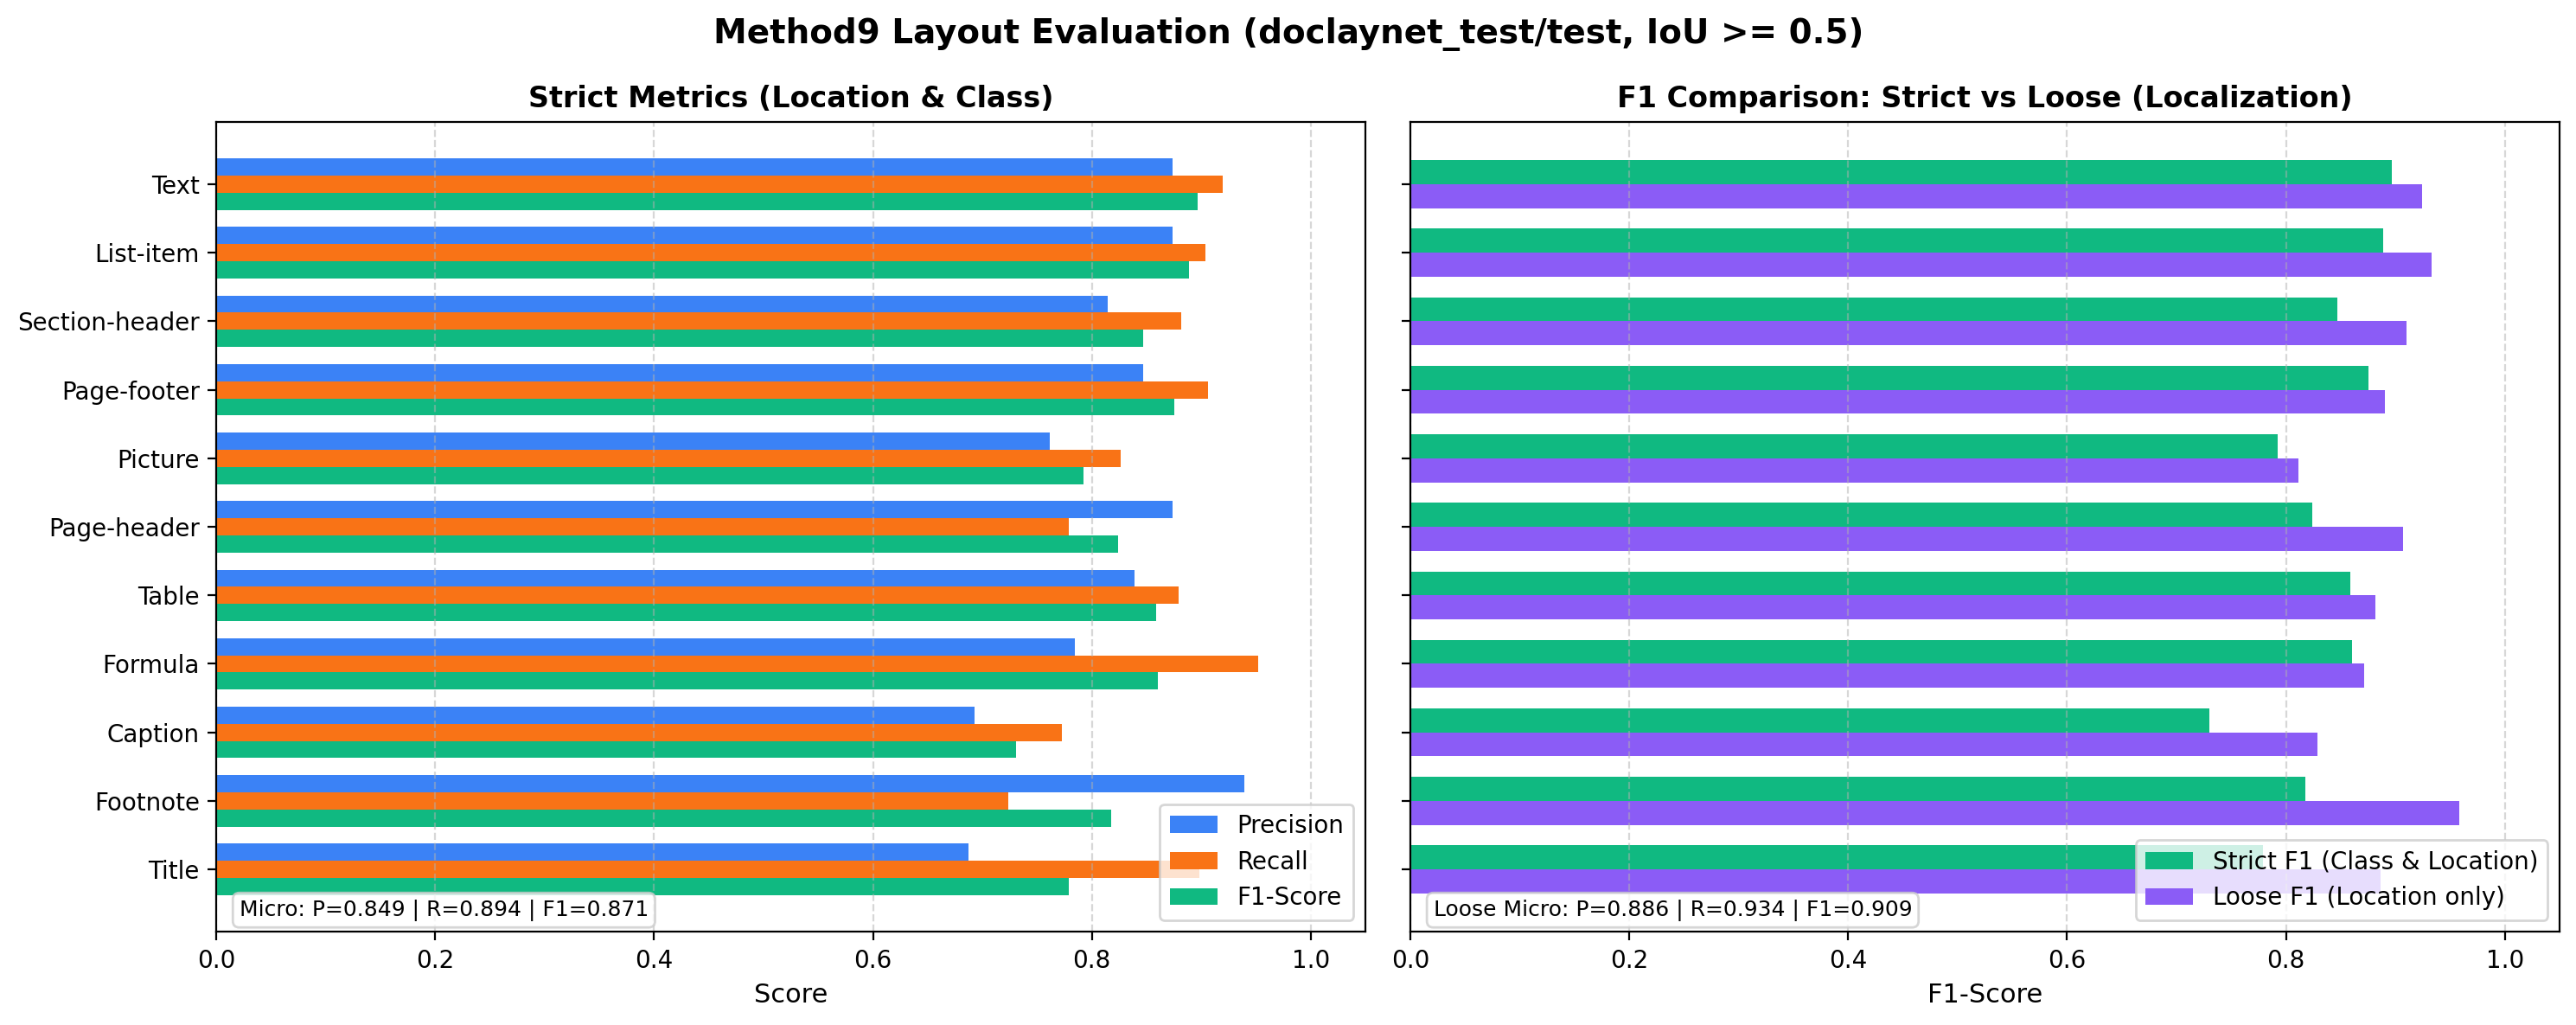

In [2]:
from IPython.display import Image as IPImage, display

chart_path = REPORTS_DIR / "metrics_chart.png"
cmd = [
    sys.executable,
    str(ROOT / "scripts" / "evaluate_predictions.py"),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", "0.5",
    "--loose",
    "--plot", str(chart_path),
]
res = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
print(res.stdout)
if chart_path.exists():
    display(IPImage(filename=str(chart_path)))

### 💡 Nhận xét kết quả Benchmark của Method 9 trên 4,999 trang:
- **Đạt kỷ lục Strict Micro F1 và End-to-End F1 (@IoU ≥ 0.50) cao nhất:**
  - **Strict Micro F1 đạt `0.871` (`87.1%`)** với sự cân bằng vượt trội giữa **Precision (`84.9%`)** và **Recall (`89.4%`)**, dẫn đầu ở các lớp tần suất cao như **`Text` (`F1 = 0.896`)**, **`List-item` (`F1 = 0.888`)**, **`Picture` (`F1 = 0.793`)**.
  - **Localization-only (Loose) Micro F1 đạt `0.909` (`90.9%`)** và **Loose Macro F1 đạt `0.891` (`89.1%`)**.
  - **End-to-End F1 tại `IoU >= 0.50` đạt `0.853` (`85.3%`)** (cao nhất trong cả 4 mô hình), và tại `IoU >= 0.75` đạt **`0.811` (`81.1%`)**.
- **Phân tích lỗi 2 giai đoạn (`print_error_analysis`):**
  - **Tỉ lệ tách box (`Split rate`) chỉ `3.26%`** (thấp hơn một nửa so với Method 8 `6.72%` và thấp hơn M2Doc `4.18%`), chứng tỏ kiến trúc YOLOv26 + Sidecar CNN giữ tính toàn vẹn của đoạn văn và danh sách rất tốt.
  - **Số lượng box dự đoán dư thừa (`Background FP`) thấp (`822` box trên 4,999 trang, trung bình chỉ `0.16` box thừa/trang)**.
  - **Độ khít biên định vị (`print_localization_reference`):** Sai lệch biên trung bình **`1.07px`**, tương đương độ lệch ngẫu nhiên **`±1.3px`** (tốt hơn Docling `±1.7px`).
- **Tốc độ suy luận thời gian thực nhanh nhất:**
  - Đạt **`50.8 FPS`** (chế độ AMP) và **`25.9 FPS`** (chế độ FP32 đầy đủ), nhanh gấp **8–14 lần** so với M2Doc (`3.6 FPS`) và **4–8 lần** so với Docling (`6.2 FPS`).

## 2. Trực Quan Hóa 10 Trang Tài Liệu Mẫu (Ground Truth vs. Method 9 Prediction)

Sử dụng `visualization/scripts/visualize_predictions.py` để vẽ đối chiếu trực tiếp **Ground Truth (bên trái)** và **Dự đoán của Method 9 (bên phải)** trên 10 trang tài liệu thuộc tập benchmark.

=== Sample Page 1 (1.png) ===
=== Sample Page 2 (2.png) ===
=== Sample Page 3 (3.png) ===
=== Sample Page 4 (4.png) ===
=== Sample Page 5 (5.png) ===
=== Sample Page 6 (6.png) ===
=== Sample Page 7 (7.png) ===
=== Sample Page 8 (8.png) ===
=== Sample Page 9 (9.png) ===
=== Sample Page 10 (10.png) ===


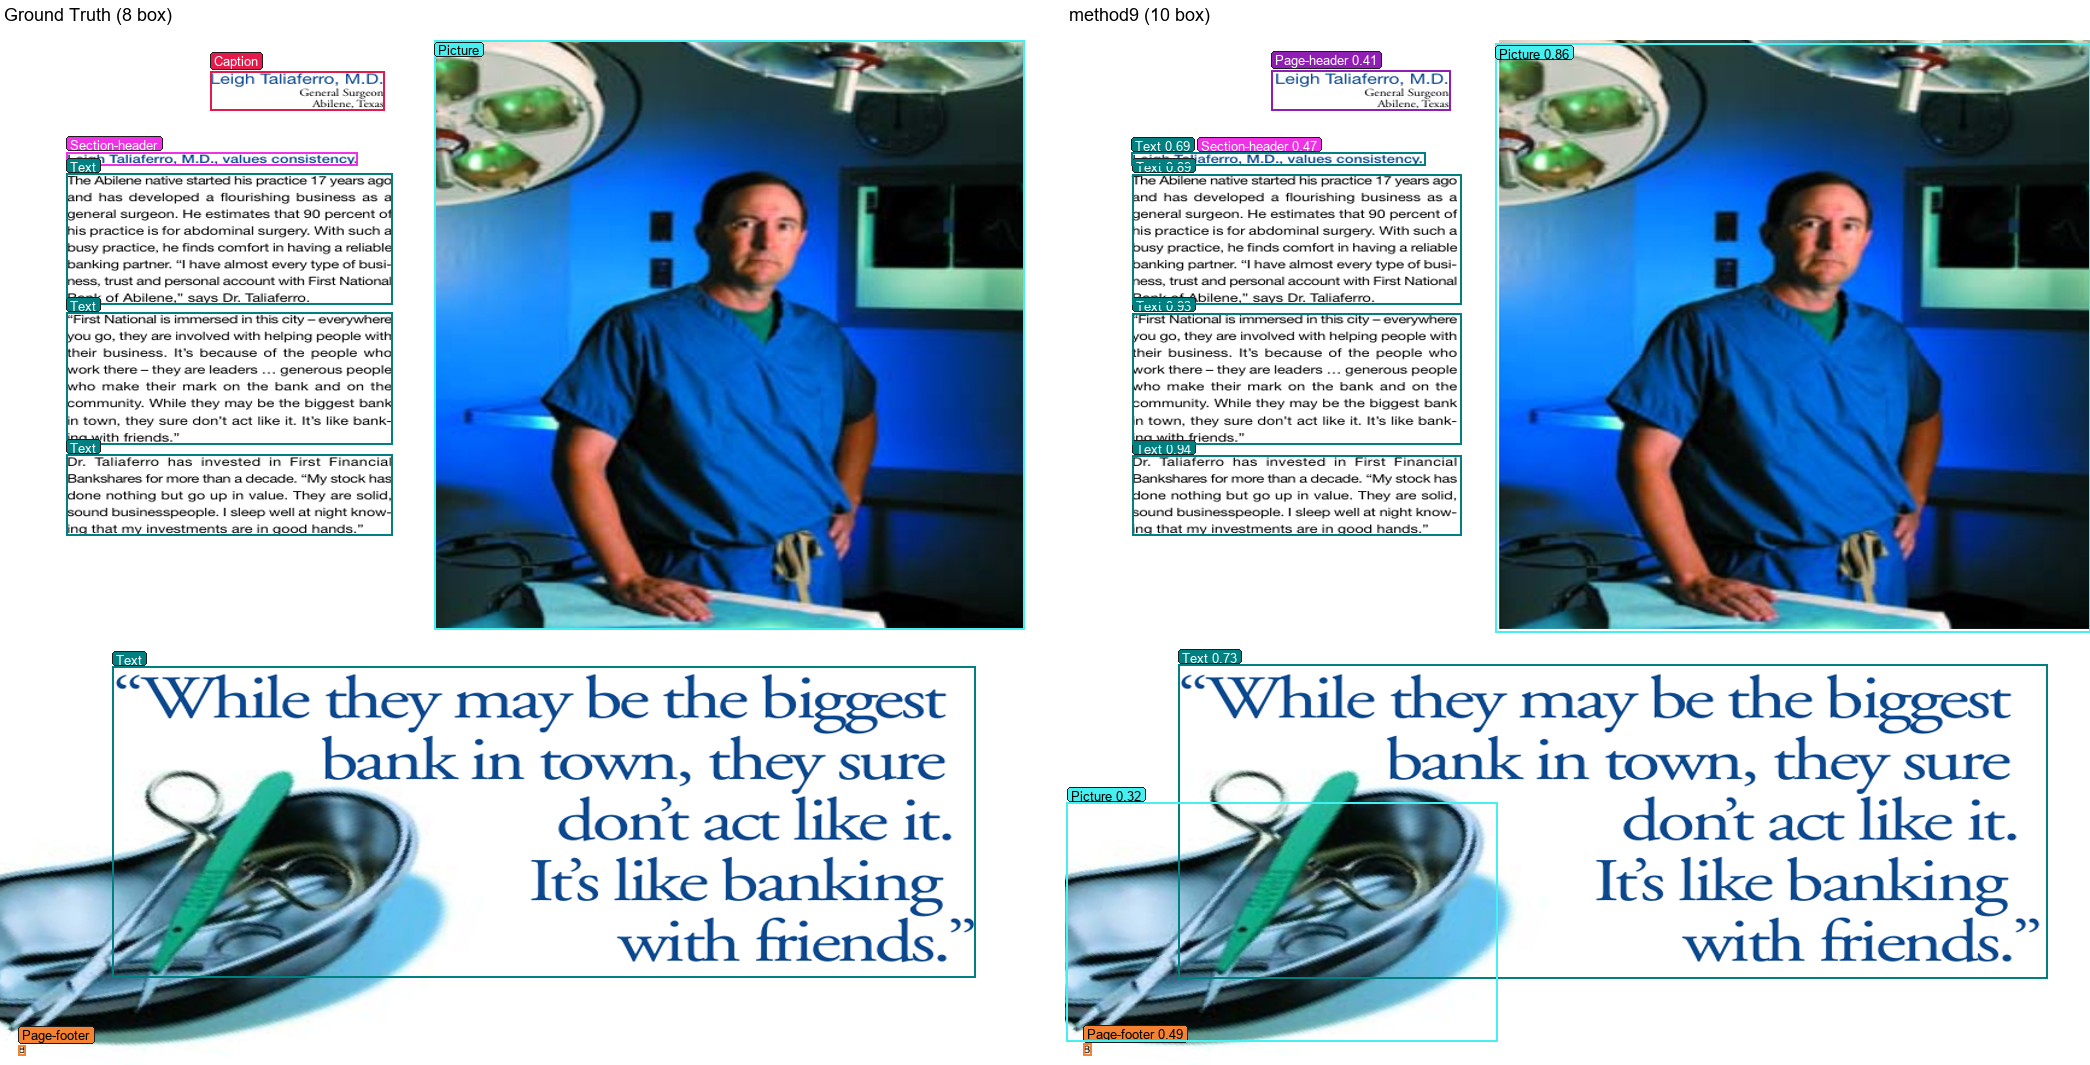

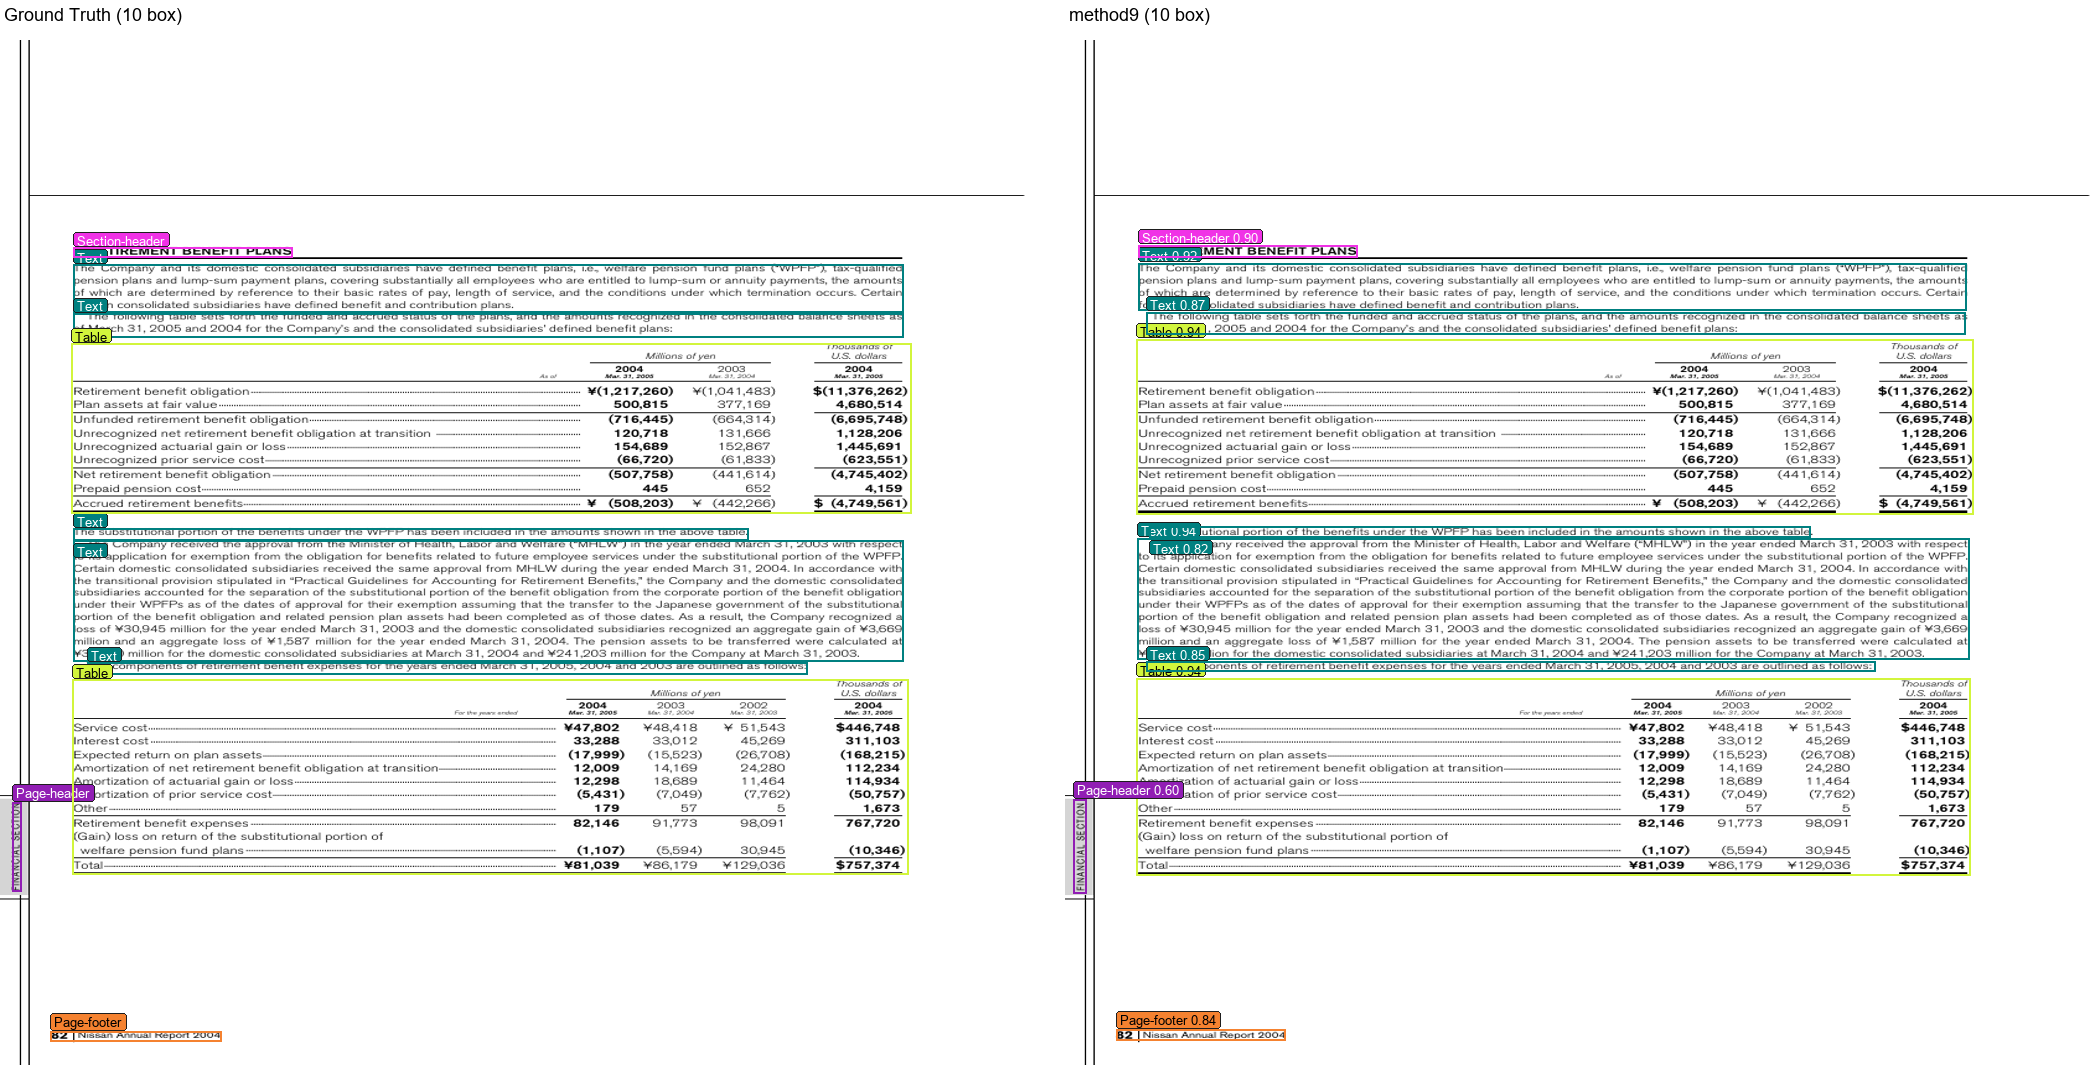

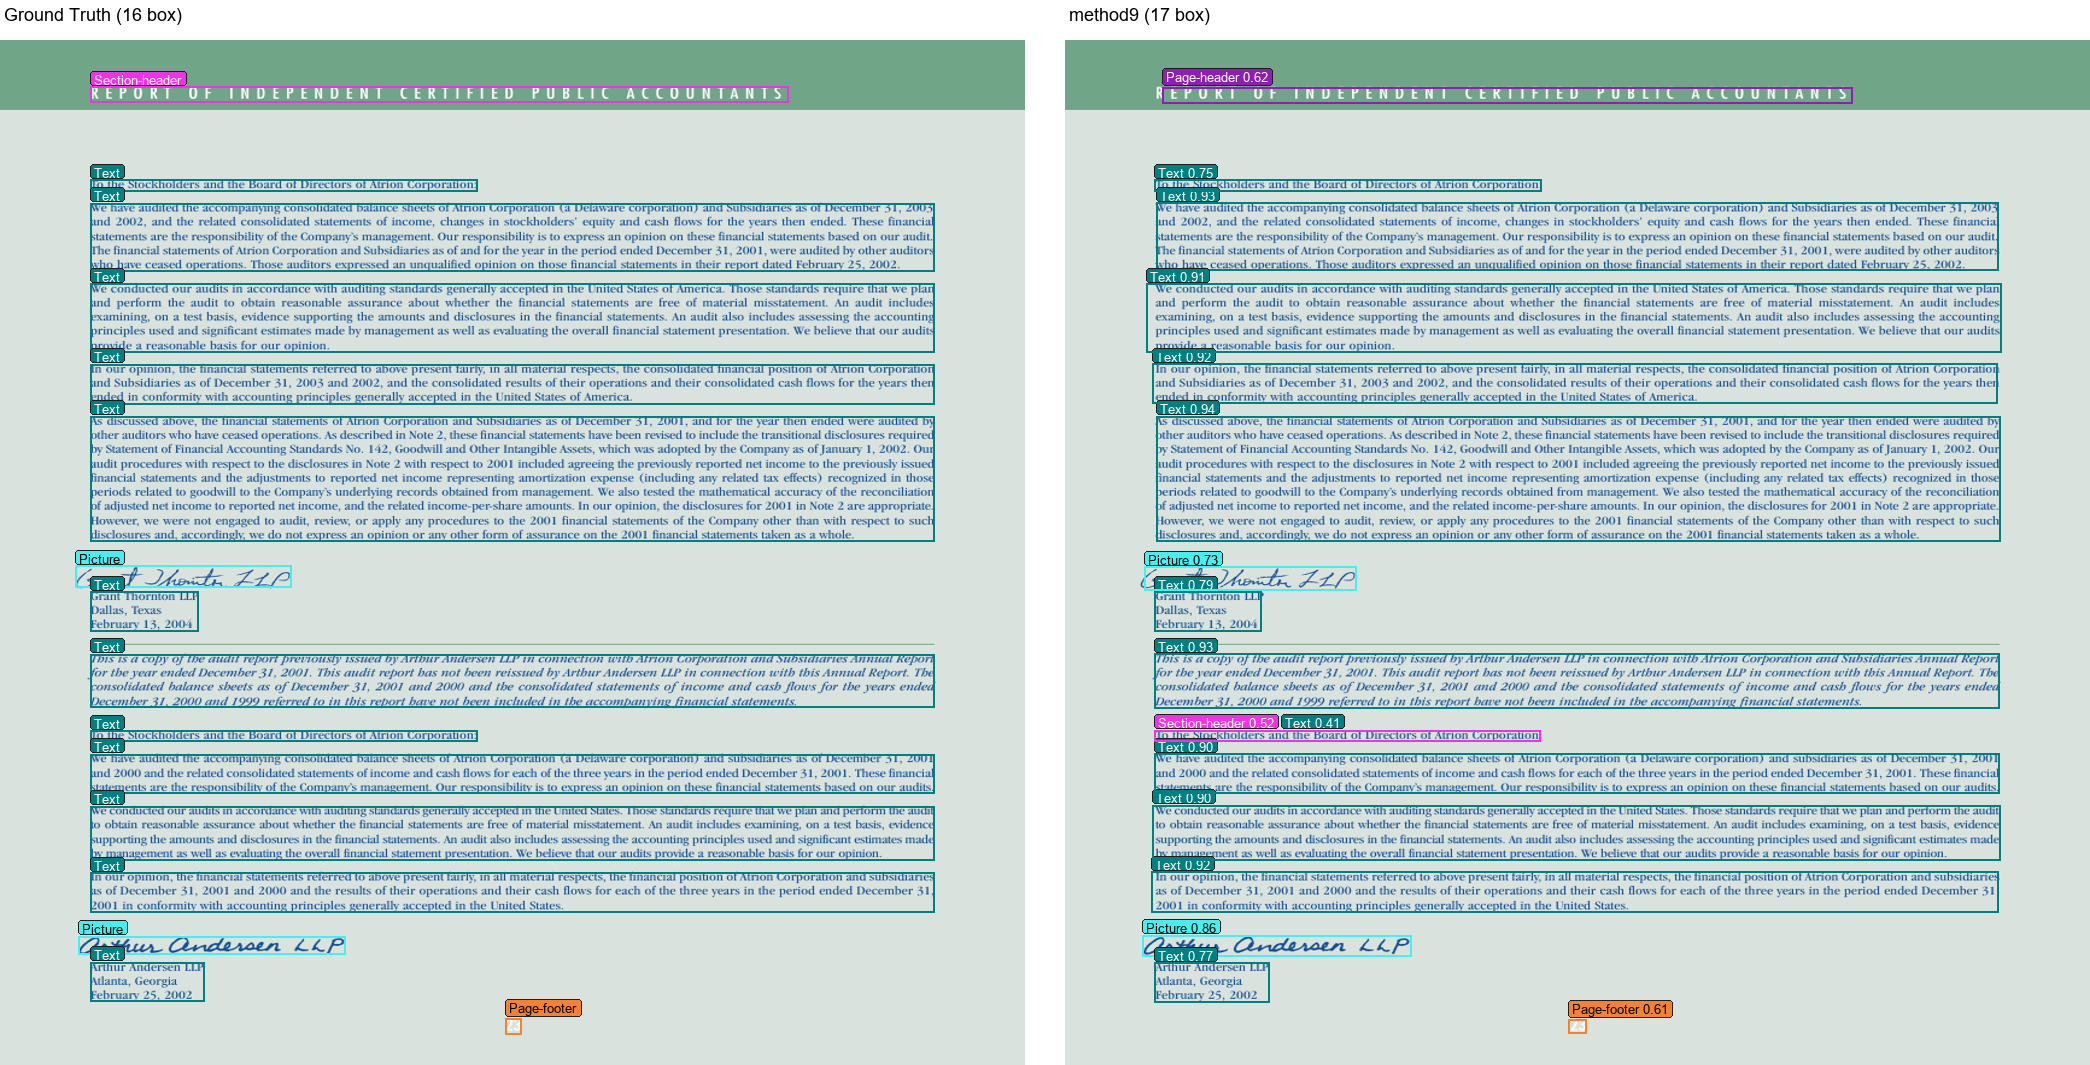

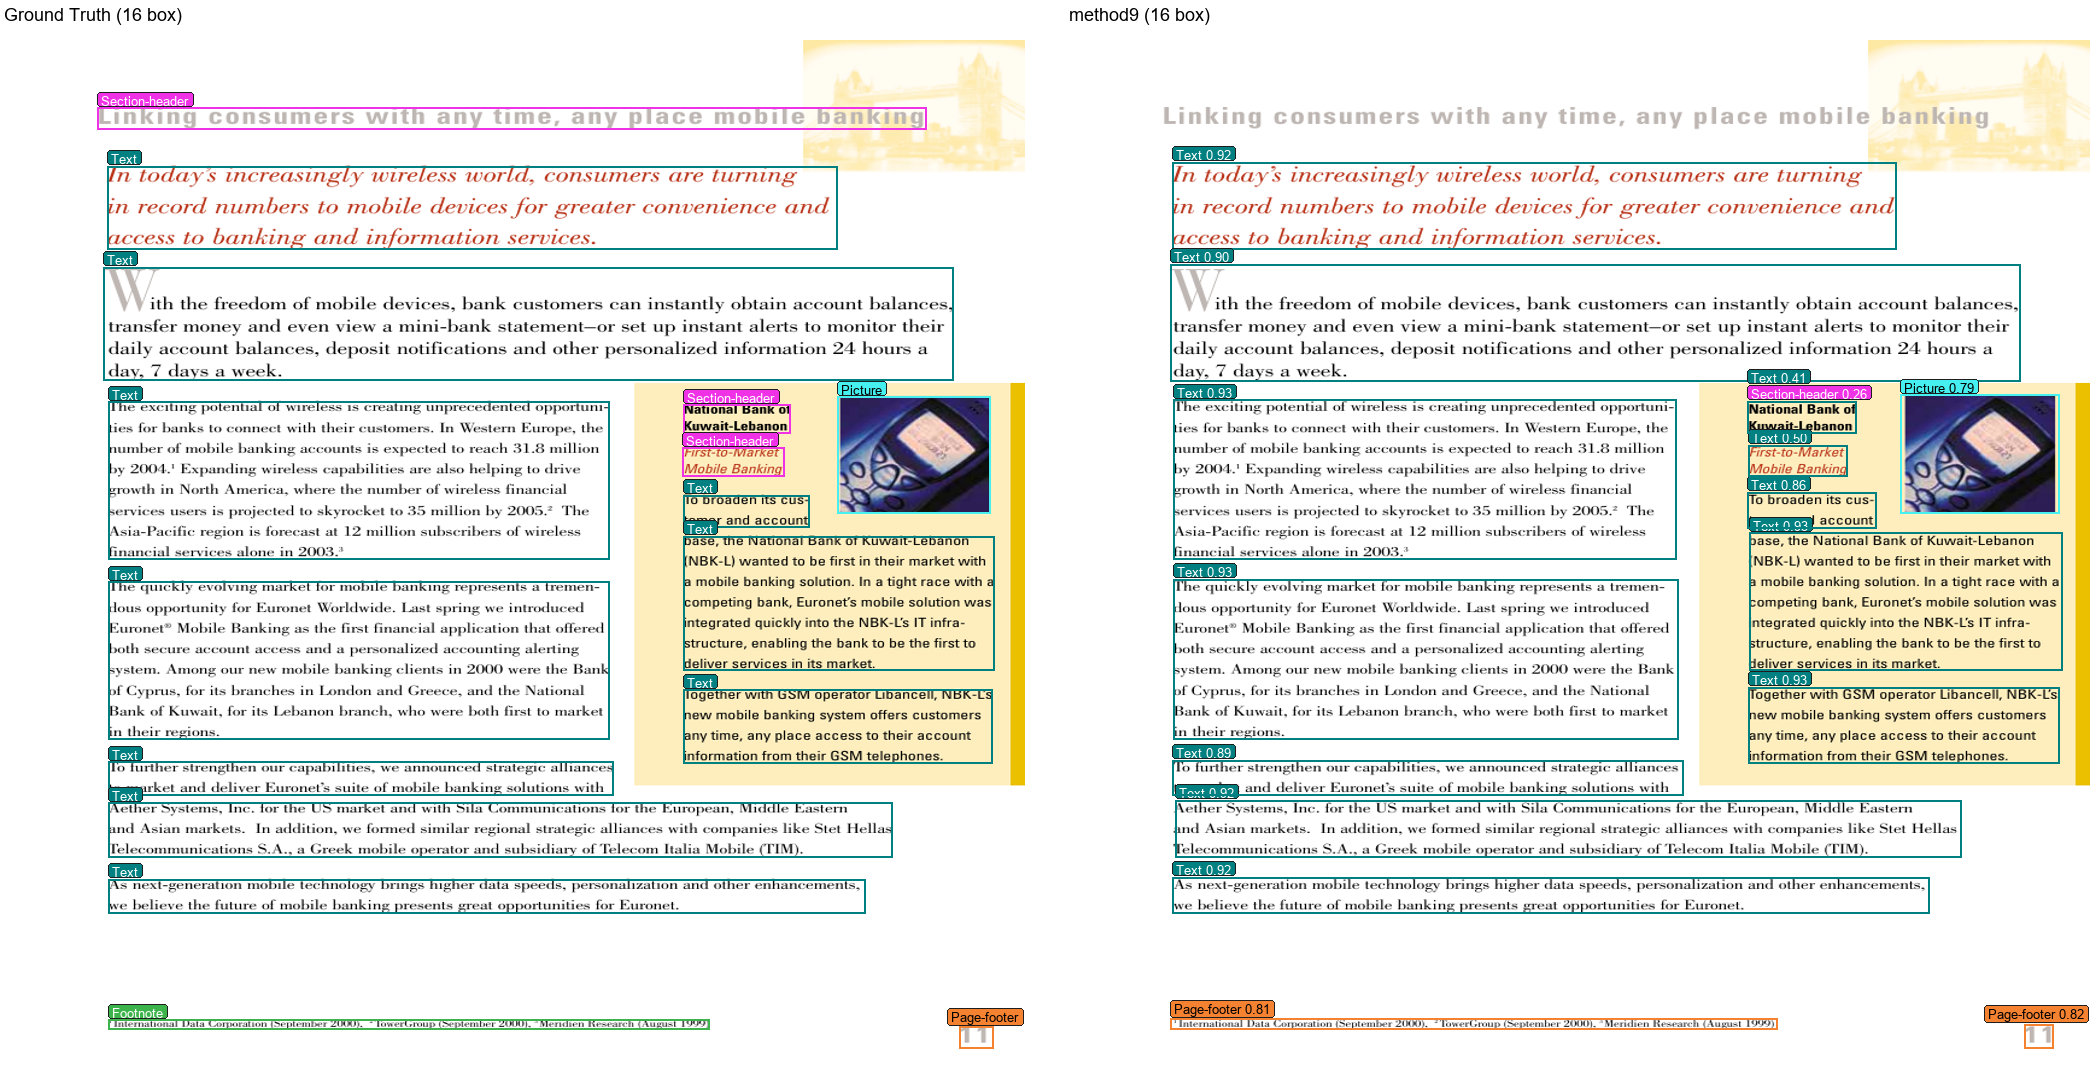

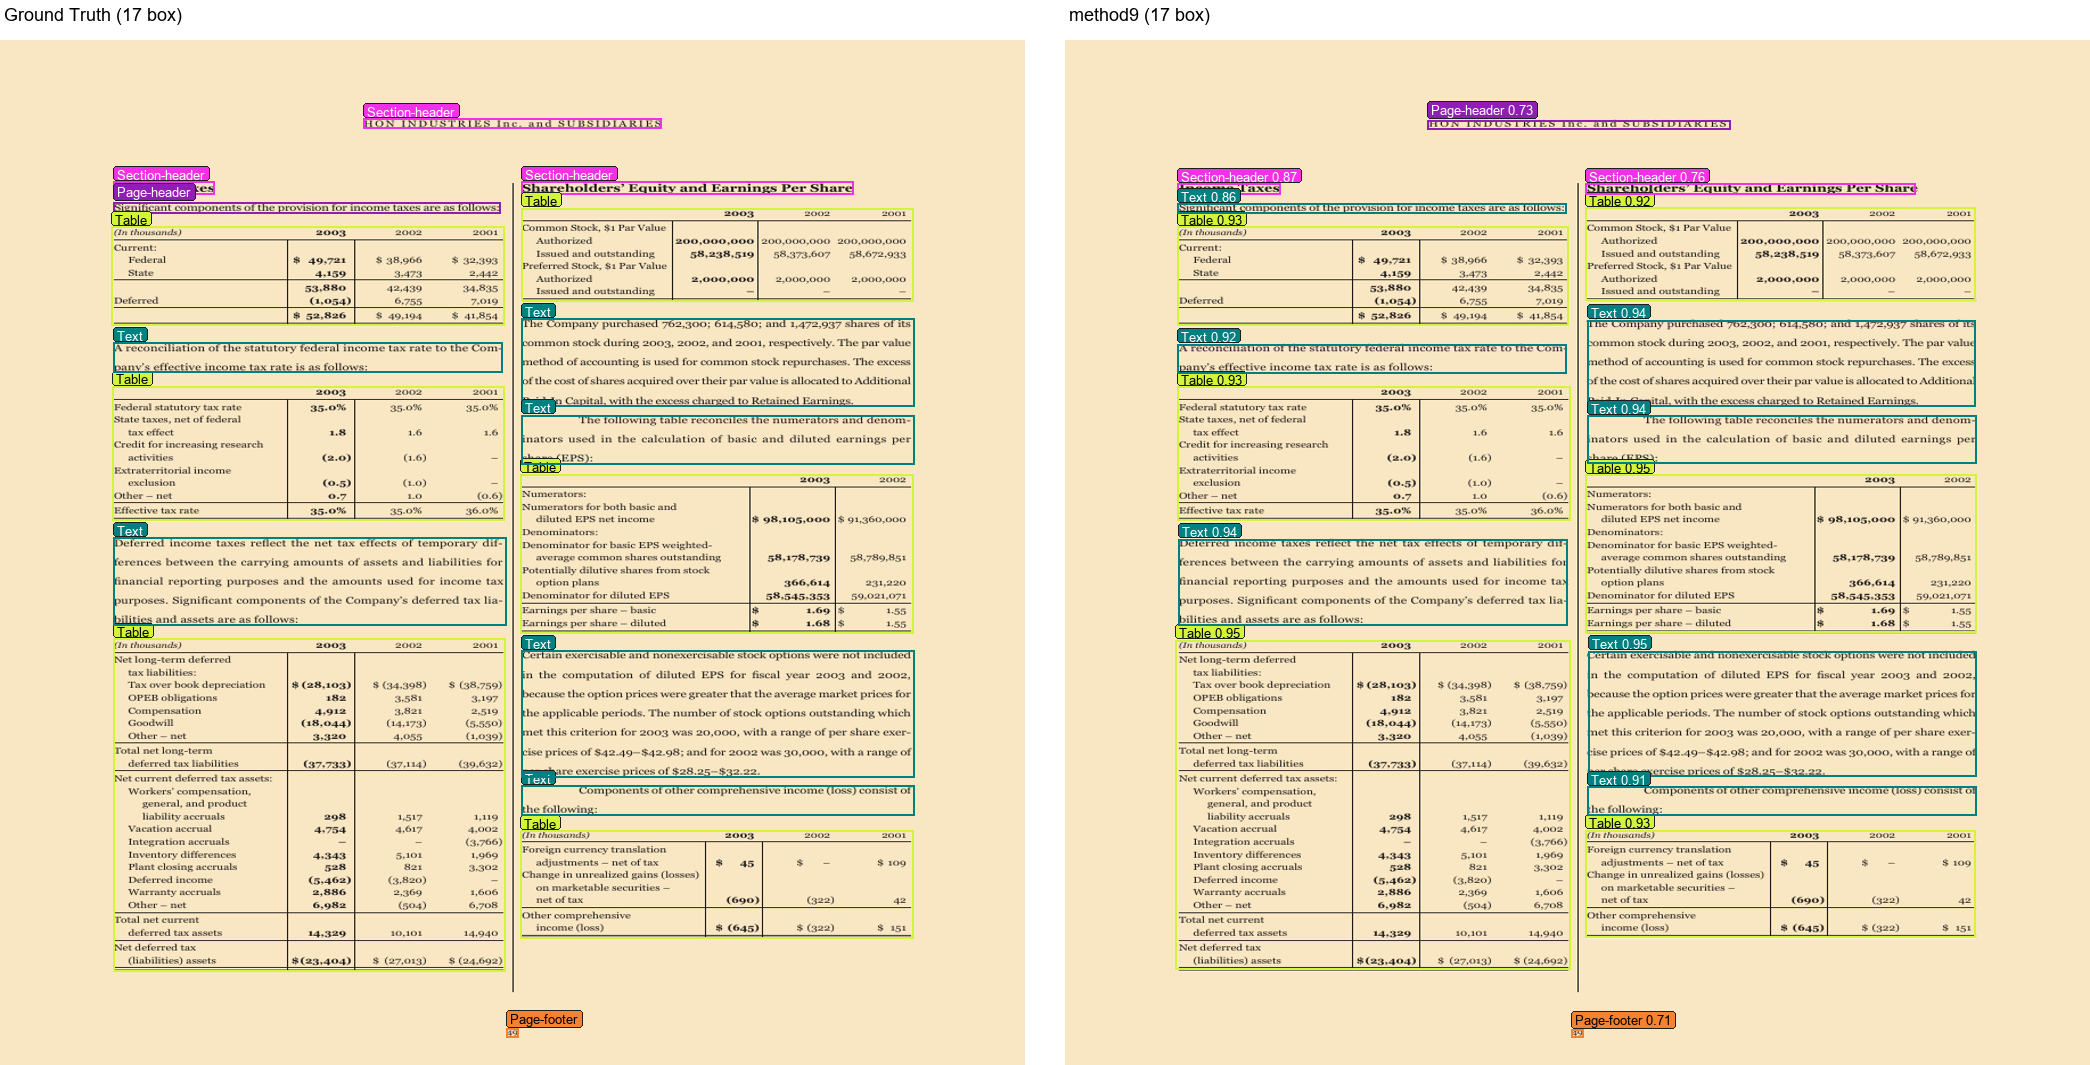

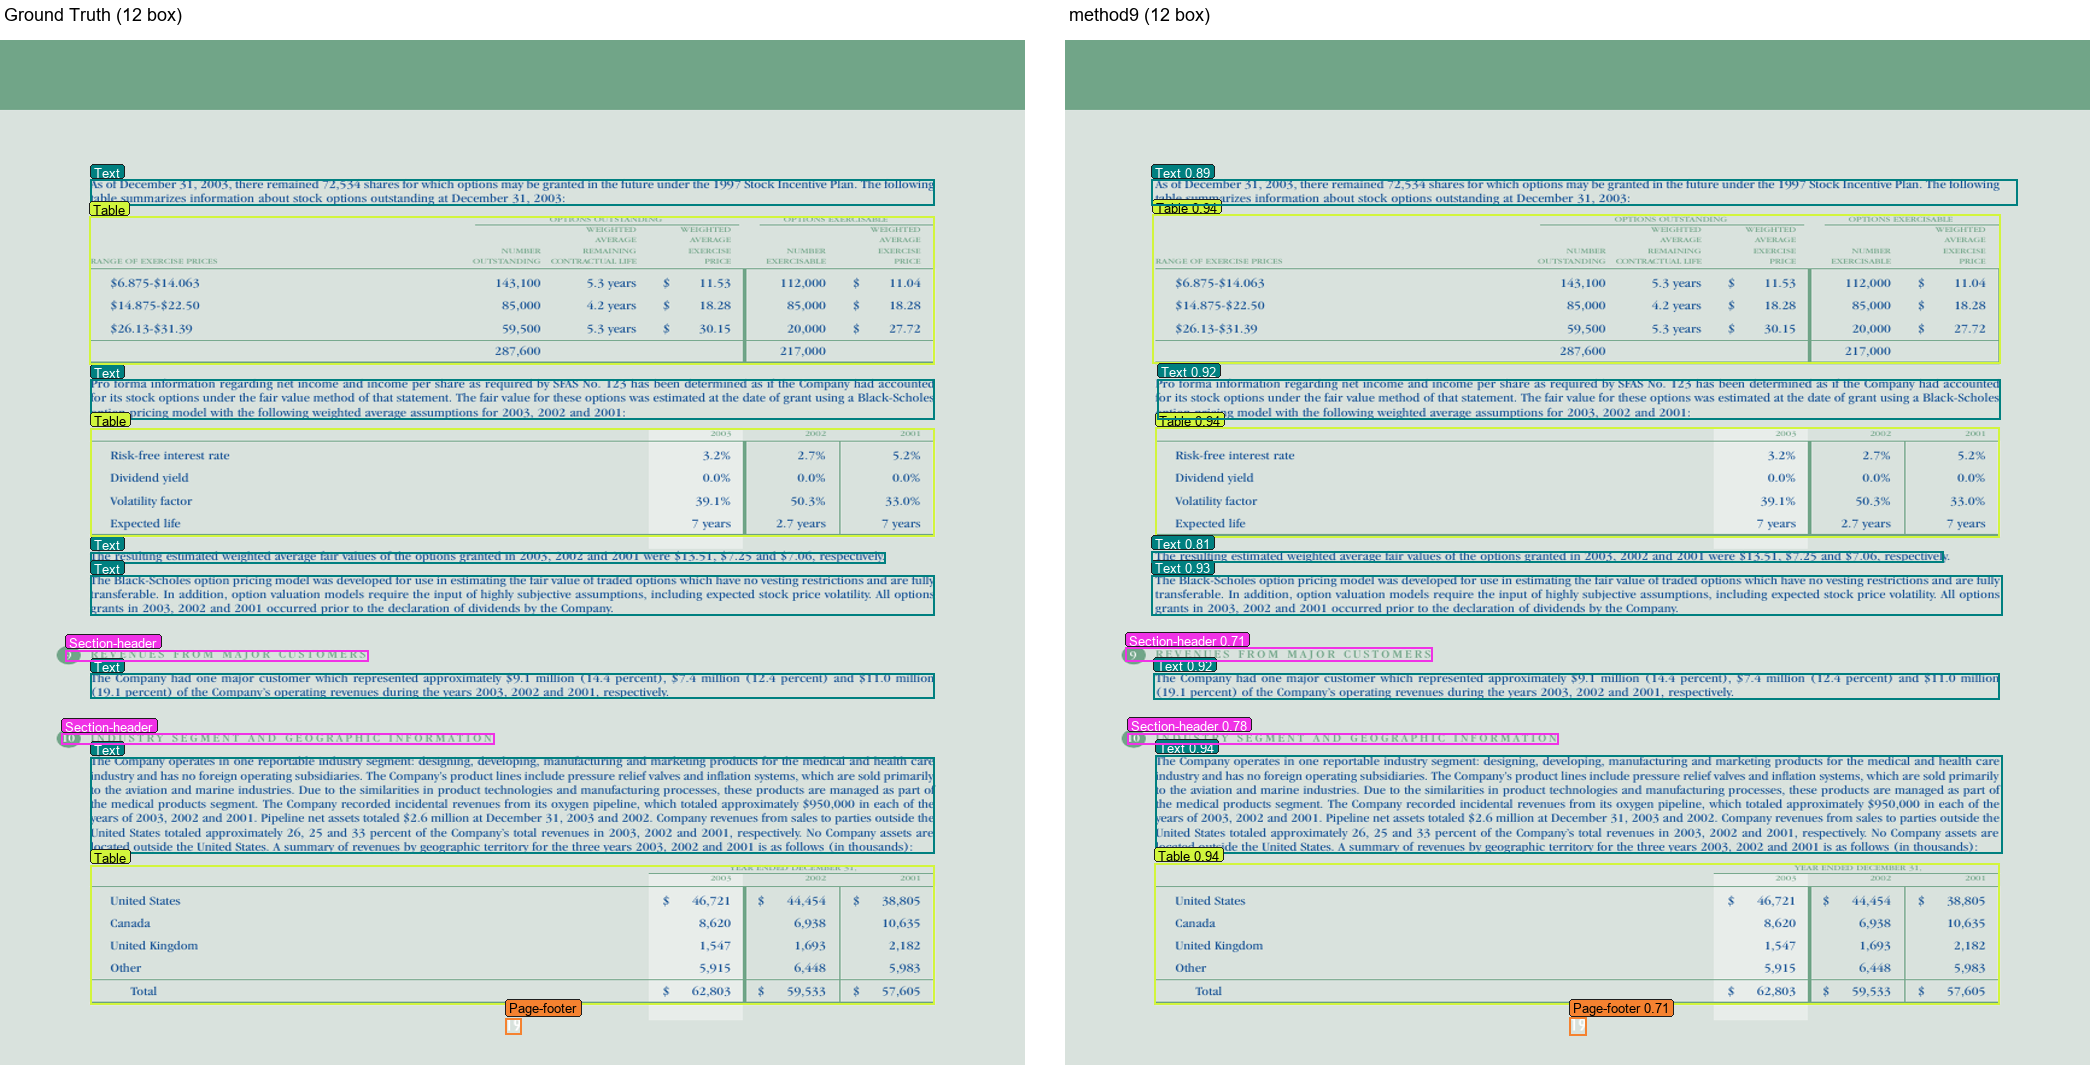

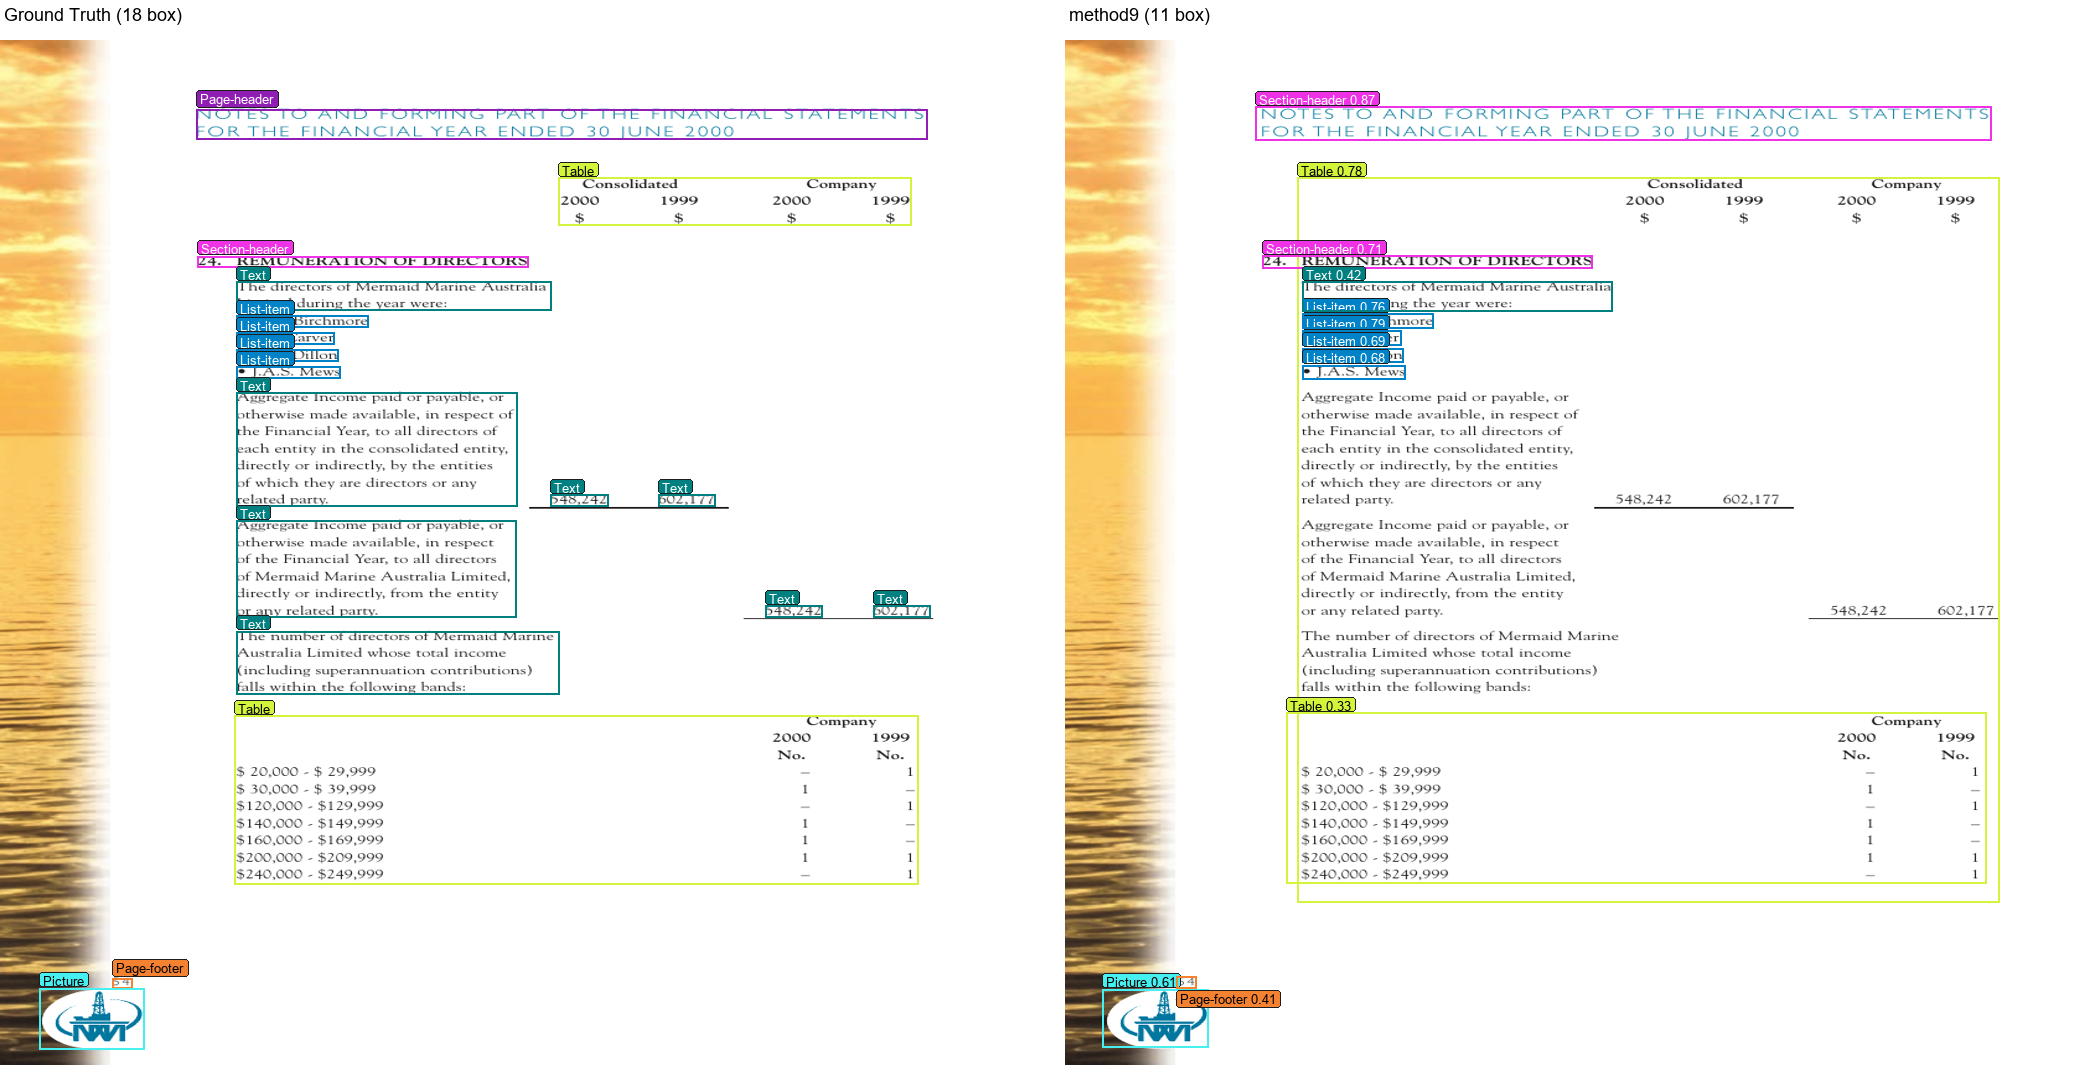

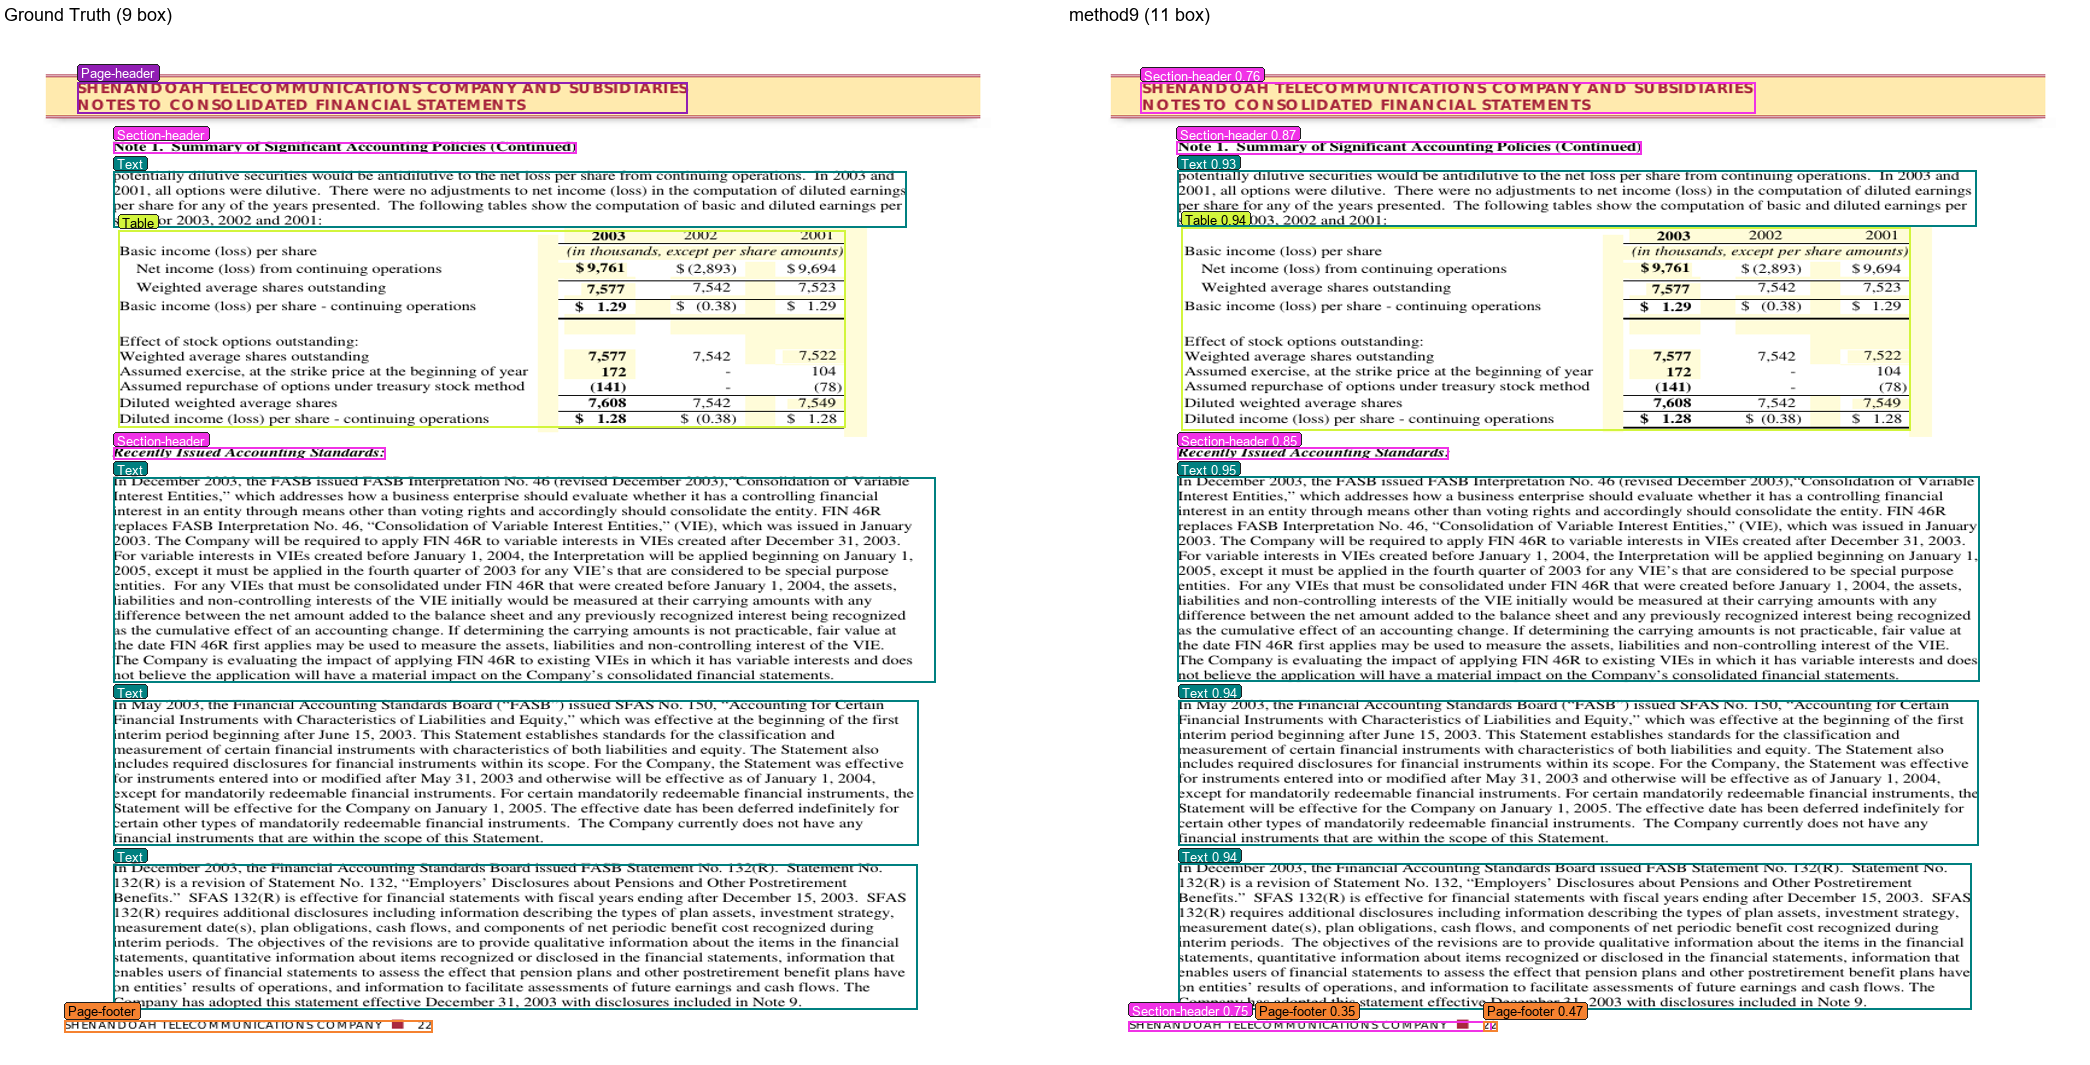

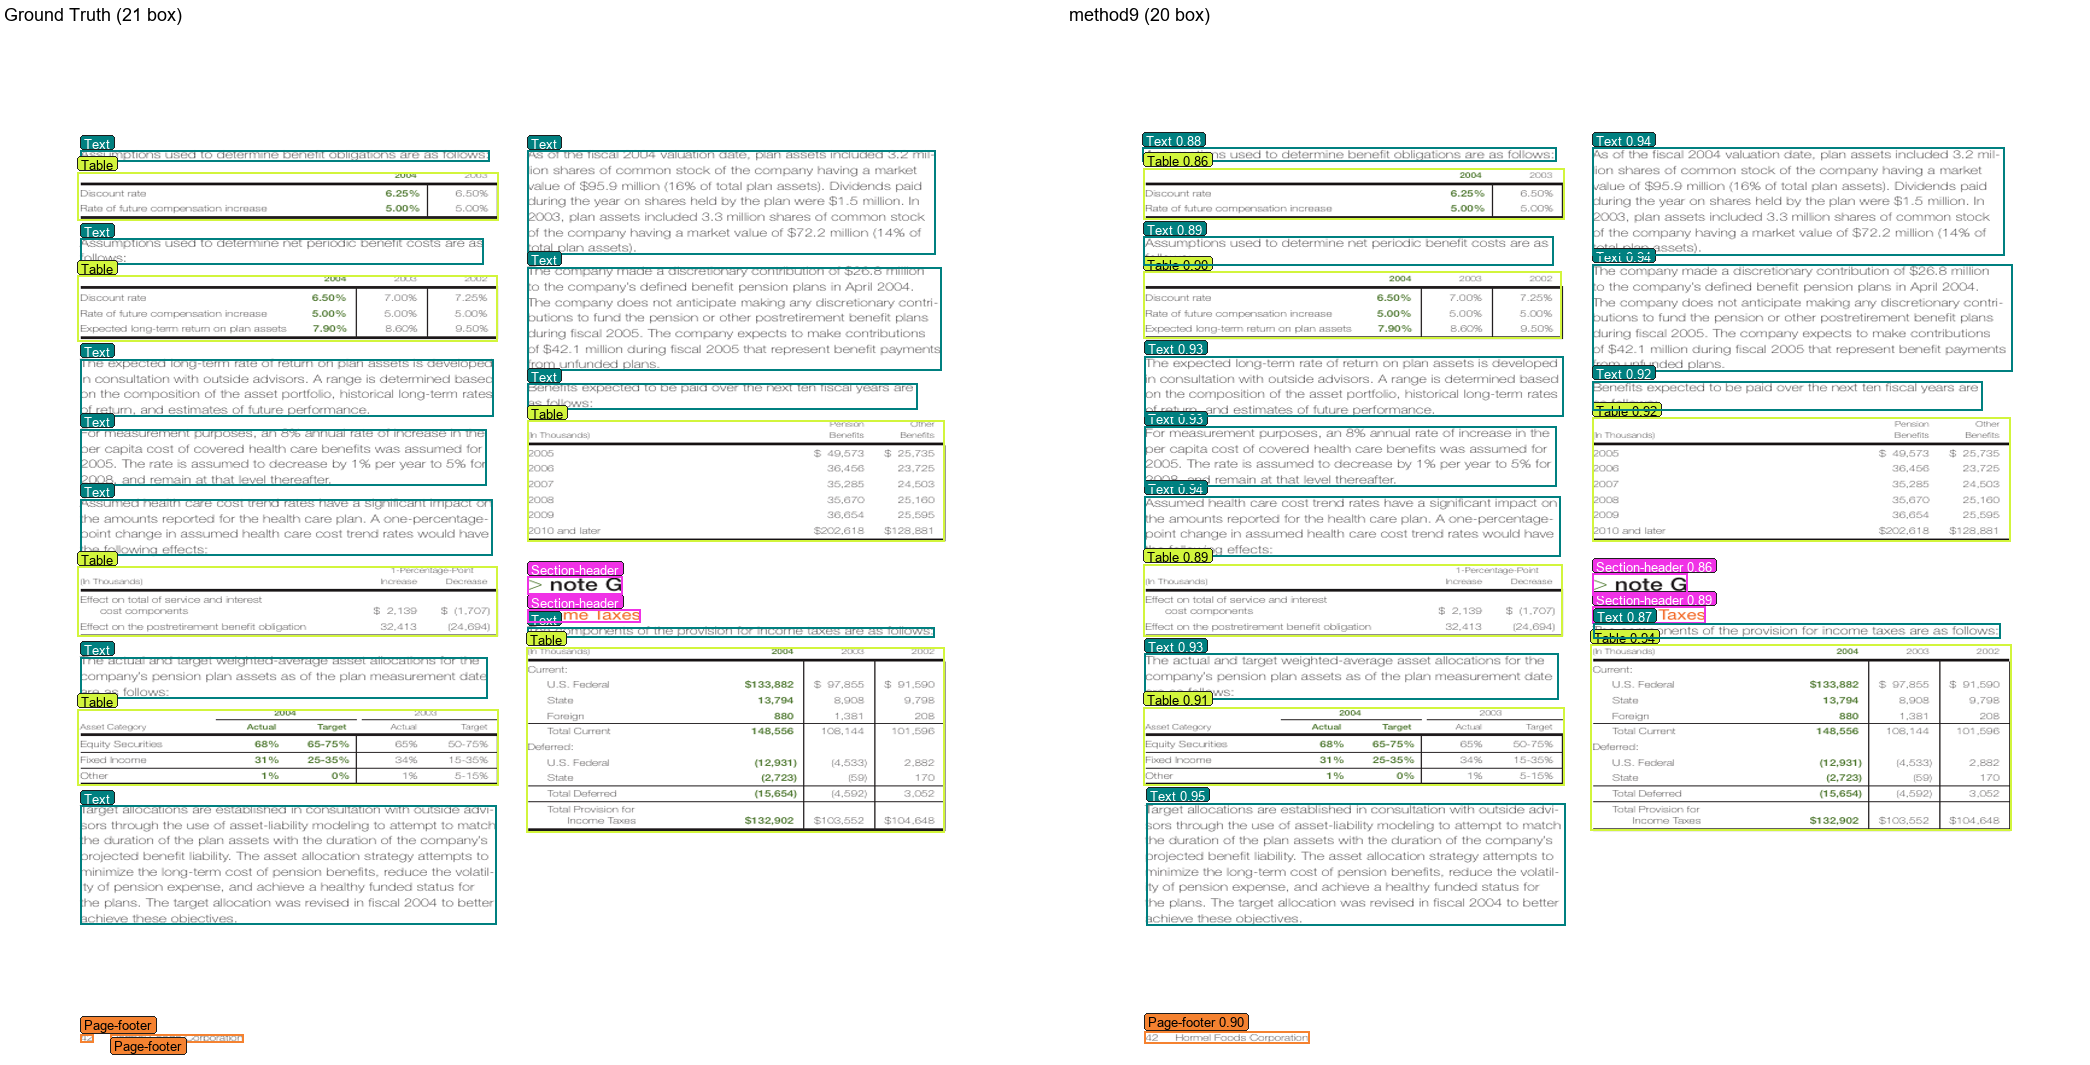

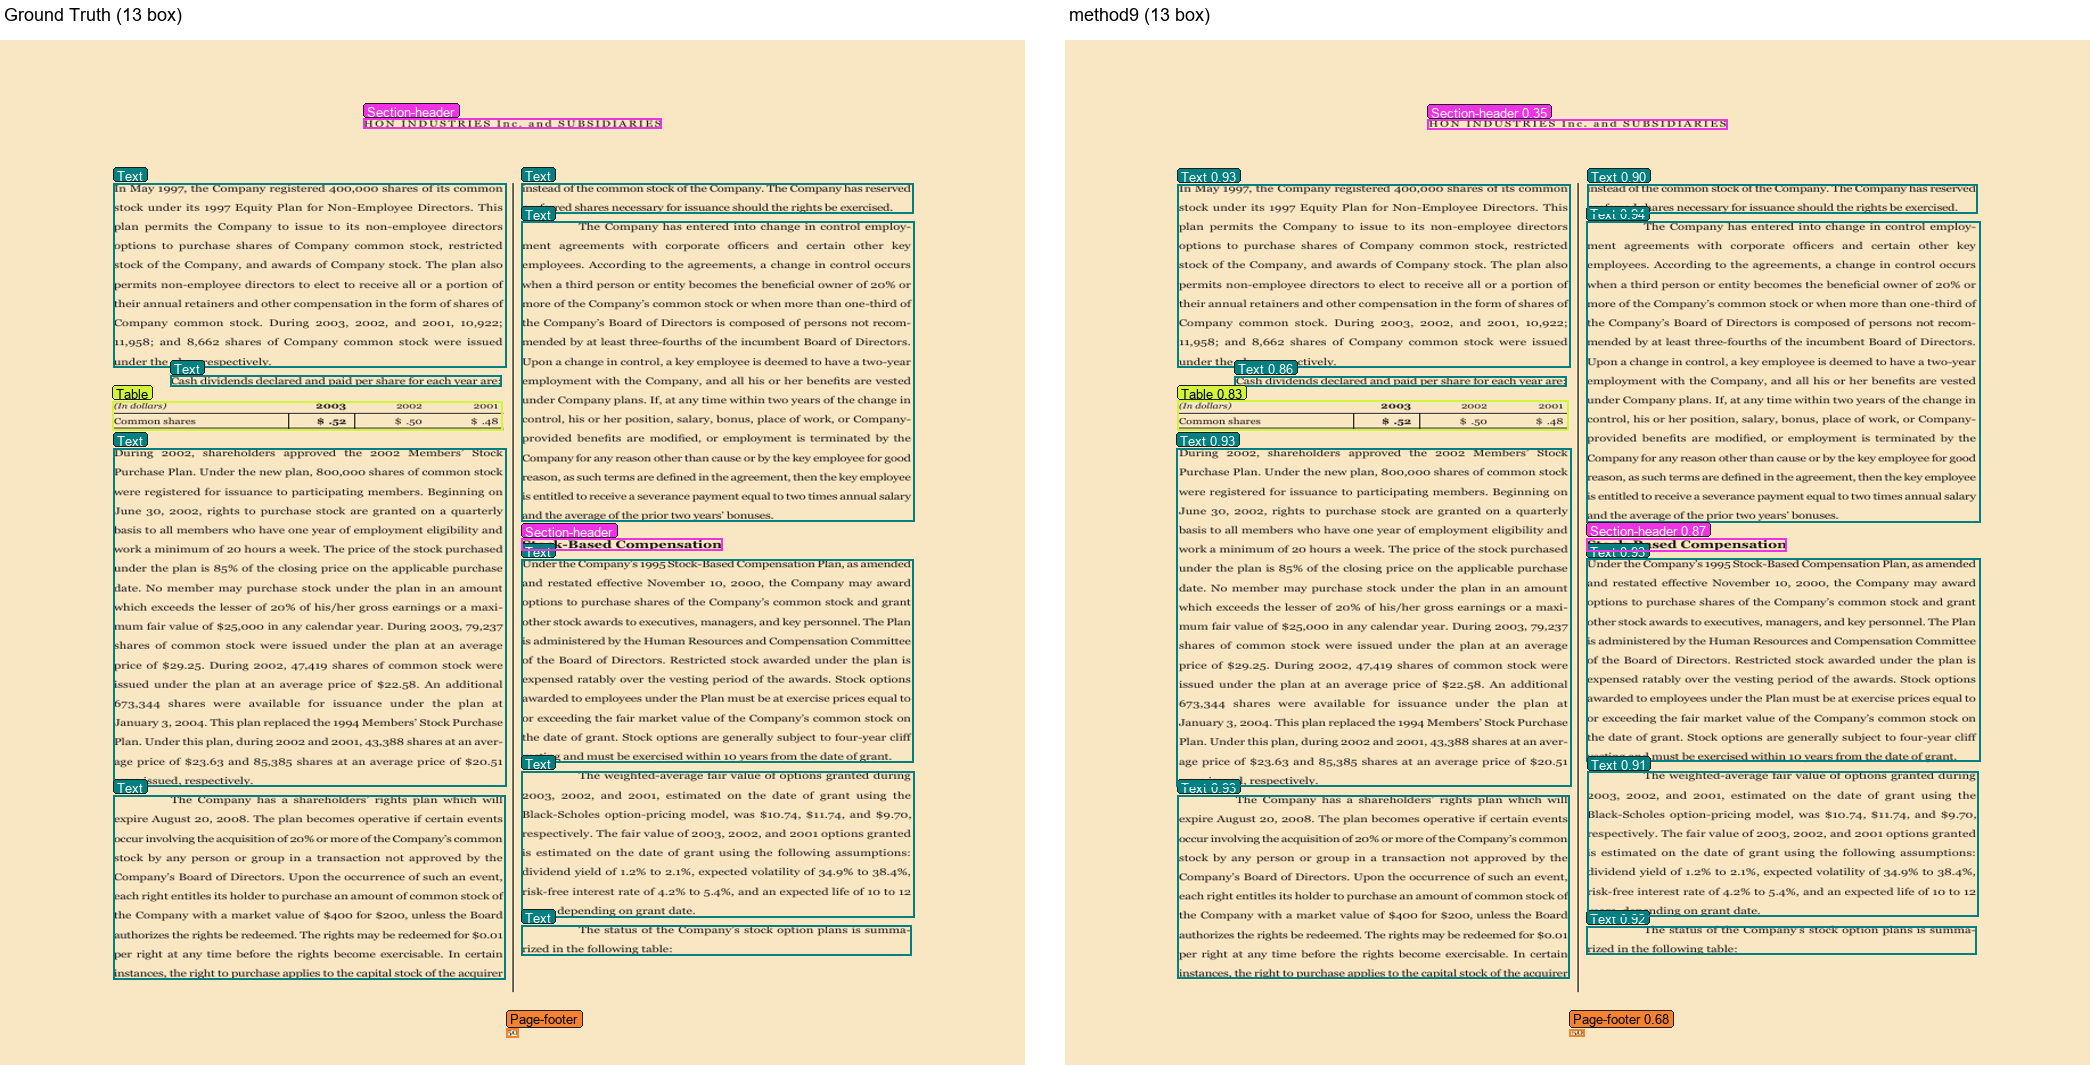

In [3]:
from IPython.display import Image as IPImage, display

vis_cmd = [
    sys.executable,
    str(ROOT / "visualization" / "scripts" / "visualize_predictions.py"),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", "10",
]
subprocess.run(vis_cmd, cwd=ROOT, check=True)

for idx in range(1, 11):
    fig_file = FIGURES_DIR / f"{idx}.png"
    if fig_file.exists():
        print(f"=== Sample Page {idx} ({fig_file.name}) ===")
        display(IPImage(filename=str(fig_file)))